# 04 — Preprocess the 10 numeric baseline features

This notebook prepares the ten understandable `static_0` features for a first logistic-regression baseline.

The aim is to learn a **repeatable and leakage-safe preprocessing process**:

1. Load only the required columns.
2. Join them to the base table by `case_id`.
3. Split applications by time **before learning preprocessing values**.
4. Inspect every feature using training data.
5. Learn median replacements and scaling values from training weeks only.
6. Apply those learned values to validation weeks.
7. Verify that the resulting matrices are ready for a model.

The model itself is deliberately left for the next notebook.

## What preprocessing means here

All ten selected predictors are numeric, so the first baseline needs two learned transformations:

- **Median imputation:** replace missing values with the median learned from training applications.
- **Missing indicators:** add a 0/1 column when a source feature was missing during training. Missingness can itself carry useful information.
- **Standard scaling:** express columns on comparable scales for logistic regression.

We will not delete outliers, convert negative DPD values to zero, create ratios, or select features in this notebook. Those would be separate experiments.

In [1]:
from pathlib import Path
import gc

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 100)

RANDOM_STATE = 42

## Locate the project and declare the ten features

The list below is the single source of truth for this notebook. `case_id`, `WEEK_NUM`, and `target` are needed for joining, splitting, and evaluation roles, but they are not predictor features.

In [2]:
possible_roots = [Path.cwd(), Path.cwd().parent]
project_dir = next(
    (path for path in possible_roots if (path / "data" / "parquet_files" / "train" / "train_base.parquet").exists()),
    None,
)
if project_dir is None:
    raise FileNotFoundError("Run this notebook from the project root or the notebooks folder.")

train_dir = project_dir / "data" / "parquet_files" / "train"
report_dir = project_dir / "reports" / "preprocessing_10_features"
report_dir.mkdir(parents=True, exist_ok=True)

selected_features = [
    "credamount_770A",
    "annuity_780A",
    "maininc_215A",
    "applications30d_658L",
    "numactivecreds_622L",
    "totaldebt_9A",
    "avgdbddpdlast24m_3658932P",
    "avgdpdtolclosure24_3658938P",
    "clientscnt12m_3712952L",
    "price_1097A",
]

print("Project:", project_dir)
print("Selected predictor count:", len(selected_features))
selected_features

Project: d:\Home Credit - Credit Risk Model Stability
Selected predictor count: 10


['credamount_770A',
 'annuity_780A',
 'maininc_215A',
 'applications30d_658L',
 'numactivecreds_622L',
 'totaldebt_9A',
 'avgdbddpdlast24m_3658932P',
 'avgdpdtolclosure24_3658938P',
 'clientscnt12m_3712952L',
 'price_1097A']

## Meanings and the planned treatment of each feature

The description comes from the competition's supplied feature dictionary. The treatment column explains what we do in this first baseline.

In [3]:
definitions = pd.read_csv(project_dir / "data" / "feature_definitions.csv")
description_map = definitions.set_index("Variable")["Description"].to_dict()

value_notes = {
    "credamount_770A": "Keep the loan amount as numeric; retain large values.",
    "annuity_780A": "Keep the annuity amount as numeric; retain large values.",
    "maininc_215A": "Keep reported income as numeric; do not replace missing income with zero.",
    "applications30d_658L": "Keep the recent-application count as numeric.",
    "numactivecreds_622L": "Keep the active-credit count as numeric.",
    "totaldebt_9A": "Keep total debt as numeric; zero and a missing value are different.",
    "avgdbddpdlast24m_3658932P": "Keep signed DPD values; negative values can represent payment before due date.",
    "avgdpdtolclosure24_3658938P": "Keep signed tolerated-DPD values; do not clip them automatically.",
    "clientscnt12m_3712952L": "Keep the shared-contact/client count as numeric.",
    "price_1097A": "Keep financed-item price as numeric; do not replace a missing price with zero.",
}

feature_plan = pd.DataFrame({
    "feature": selected_features,
    "meaning": [description_map.get(feature, "Description unavailable") for feature in selected_features],
    "value_treatment": [value_notes[feature] for feature in selected_features],
    "missing_treatment": "Training median; add a missing flag only when training has missing values.",
    "scaling": "StandardScaler fitted on training weeks only.",
    "outliers": "Retain for the first baseline; investigate in a later controlled experiment.",
}).set_index("feature")

display(feature_plan)

,meaning,value_treatment,missing_treatment,scaling,outliers
feature,,,,,
credamount_770A,Loan amount or credit card limit.,Keep the loan amount as numeric; retain large values.,Training median; add a missing flag only when training has missing values.,StandardScaler fitted on training weeks only.,Retain for the first baseline; investigate in a later controlled experiment.
annuity_780A,Monthly annuity amount.,Keep the annuity amount as numeric; retain large values.,Training median; add a missing flag only when training has missing values.,StandardScaler fitted on training weeks only.,Retain for the first baseline; investigate in a later controlled experiment.
maininc_215A,Client's primary income amount.,Keep reported income as numeric; do not replace missing income with zero.,Training median; add a missing flag only when training has missing values.,StandardScaler fitted on training weeks only.,Retain for the first baseline; investigate in a later controlled experiment.
applications30d_658L,Number of applications made by the client in the last 30 days.,Keep the recent-application count as numeric.,Training median; add a missing flag only when training has missing values.,StandardScaler fitted on training weeks only.,Retain for the first baseline; investigate in a later controlled experiment.
numactivecreds_622L,Number of active credits.,Keep the active-credit count as numeric.,Training median; add a missing flag only when training has missing values.,StandardScaler fitted on training weeks only.,Retain for the first baseline; investigate in a later controlled experiment.
totaldebt_9A,Total amount of debt.,Keep total debt as numeric; zero and a missing value are different.,Training median; add a missing flag only when training has missing values.,StandardScaler fitted on training weeks only.,Retain for the first baseline; investigate in a later controlled experiment.
avgdbddpdlast24m_3658932P,Average days past or before due of payment during the last 24 months.,Keep signed DPD values; negative values can represent payment before due date.,Training median; add a missing flag only when training has missing values.,StandardScaler fitted on training weeks only.,Retain for the first baseline; investigate in a later controlled experiment.
avgdpdtolclosure24_3658938P,Average DPD (days past due) with tolerance within the past 24 months from the maximum closure da...,Keep signed tolerated-DPD values; do not clip them automatically.,Training median; add a missing flag only when training has missing values.,StandardScaler fitted on training weeks only.,Retain for the first baseline; investigate in a later controlled experiment.
clientscnt12m_3712952L,Number of clients that have used the same mobile phone as the applicant in the past 12 months.,Keep the shared-contact/client count as numeric.,Training median; add a missing flag only when training has missing values.,StandardScaler fitted on training weeks only.,Retain for the first baseline; investigate in a later controlled experiment.


## Load only the required columns

Parquet lets pandas read selected columns. This is much more memory-efficient than loading all 168 `static_0` columns.

In [4]:
base = pd.read_parquet(
    train_dir / "train_base.parquet",
    columns=["case_id", "WEEK_NUM", "target"],
)

static_paths = [
    train_dir / "train_static_0_0.parquet",
    train_dir / "train_static_0_1.parquet",
]
static = pd.concat(
    [
        pd.read_parquet(path, columns=["case_id", *selected_features])
        for path in static_paths
    ],
    ignore_index=True,
)

print(f"Base:   {base.shape[0]:,} rows × {base.shape[1]} columns")
print(f"Static: {static.shape[0]:,} rows × {static.shape[1]} columns")
print(f"Approximate loaded memory: {(base.memory_usage(deep=True).sum() + static.memory_usage(deep=True).sum()) / 1024**2:,.1f} MB")

Base:   1,526,659 rows × 3 columns
Static: 1,526,659 rows × 11 columns
Approximate loaded memory: 163.1 MB


## Validate the join

Both tables should have one row per application. We join on `case_id`; row position is not a safe join method.

In [5]:
assert base["case_id"].is_unique, "Base contains duplicate case_id values."
assert static["case_id"].is_unique, "static_0 contains duplicate case_id values."
assert set(selected_features).issubset(static.columns)
assert base["target"].notna().all()

modeling_data = base.merge(
    static,
    on="case_id",
    how="left",
    validate="one_to_one",
    indicator=True,
)

join_counts = modeling_data["_merge"].value_counts()
display(join_counts.to_frame("applications"))
assert (modeling_data["_merge"] == "both").all(), "Some base applications did not match static_0."

modeling_data = modeling_data.drop(columns="_merge")
del base, static
gc.collect()

print(f"Modeling table: {modeling_data.shape[0]:,} rows × {modeling_data.shape[1]} columns")

,applications
_merge,
both,1526659
left_only,0
right_only,0


Modeling table: 1,526,659 rows × 13 columns


## Split by time before preprocessing

We use earlier applications to predict later applications:

| Role | Weeks | What we may do |
|---|---:|---|
| Training | 0–51 | Fit preprocessing values |
| Development validation | 52–71 | Transform and compare development choices |
| Locked final holdout | 72–91 | Keep untouched until the final model decision |

We report only the locked holdout's size and week range. We do not inspect its targets or feature distributions here.

In [6]:
train_mask = modeling_data["WEEK_NUM"].between(0, 51)
valid_mask = modeling_data["WEEK_NUM"].between(52, 71)
locked_mask = modeling_data["WEEK_NUM"].between(72, 91)

membership_count = train_mask.astype("int8") + valid_mask.astype("int8") + locked_mask.astype("int8")
assert membership_count.eq(1).all(), "Every row must belong to exactly one split."
assert modeling_data.loc[train_mask, "WEEK_NUM"].max() < modeling_data.loc[valid_mask, "WEEK_NUM"].min()
assert modeling_data.loc[valid_mask, "WEEK_NUM"].max() < modeling_data.loc[locked_mask, "WEEK_NUM"].min()

X_train = modeling_data.loc[train_mask, selected_features].copy()
y_train = modeling_data.loc[train_mask, "target"].copy()
X_valid = modeling_data.loc[valid_mask, selected_features].copy()
y_valid = modeling_data.loc[valid_mask, "target"].copy()

assert X_train.columns.tolist() == selected_features
assert X_valid.columns.tolist() == selected_features
assert y_train.nunique() == 2 and y_valid.nunique() == 2

split_summary = pd.DataFrame({
    "period": ["Training", "Development validation", "Locked final holdout"],
    "weeks": ["0–51", "52–71", "72–91"],
    "rows": [int(train_mask.sum()), int(valid_mask.sum()), int(locked_mask.sum())],
})
display(split_summary)

print(
    "Locked holdout preserved:",
    f"{locked_mask.sum():,} rows,",
    f"weeks {modeling_data.loc[locked_mask, 'WEEK_NUM'].min()}–{modeling_data.loc[locked_mask, 'WEEK_NUM'].max()}",
)

,period,weeks,rows
0,Training,0–51,1065921
1,Development validation,52–71,248535
2,Locked final holdout,72–91,212203


Locked holdout preserved: 212,203 rows, weeks 72–91


## Inspect each feature using training rows

This audit tells us what the preprocessor must handle. The percentiles describe the data but do not alter it. Negative values are not automatically errors: the two DPD columns can use negative values for payments made before a due date.

In [7]:
def count_infinite(series):
    values = pd.to_numeric(series, errors="coerce").to_numpy(dtype="float64", na_value=np.nan)
    return int(np.isinf(values).sum())

train_quantiles = X_train.quantile([0.01, 0.50, 0.99]).T
feature_audit = pd.DataFrame(index=selected_features)
feature_audit.index.name = "feature"
feature_audit["meaning"] = [description_map.get(feature, "Description unavailable") for feature in selected_features]
feature_audit["dtype"] = X_train.dtypes.astype(str)
feature_audit["missing_count"] = X_train.isna().sum()
feature_audit["missing_percent"] = X_train.isna().mean().mul(100)
feature_audit["unique_non_null"] = X_train.nunique(dropna=True)
feature_audit["minimum"] = X_train.min()
feature_audit["p01"] = train_quantiles[0.01]
feature_audit["median"] = train_quantiles[0.50]
feature_audit["p99"] = train_quantiles[0.99]
feature_audit["maximum"] = X_train.max()
feature_audit["zero_percent"] = X_train.eq(0).mean().mul(100)
feature_audit["negative_percent"] = X_train.lt(0).mean().mul(100)
feature_audit["infinite_count"] = [count_infinite(X_train[feature]) for feature in selected_features]
feature_audit["skewness"] = X_train.skew(numeric_only=True)
feature_audit["planned_missing_action"] = np.where(
    feature_audit["missing_count"].gt(0),
    "Median imputation + missing indicator",
    "No missing values observed; median imputer remains in pipeline",
)

feature_audit.to_csv(report_dir / "training_feature_audit.csv")
display(feature_audit.round(3))

assert feature_audit["infinite_count"].eq(0).all(), "Infinity found. Convert it to NaN before imputation."

,meaning,dtype,missing_count,missing_percent,unique_non_null,minimum,p01,median,p99,maximum,zero_percent,negative_percent,infinite_count,skewness,planned_missing_action
feature,,,,,,,,,,,,,,,
credamount_770A,Loan amount or credit card limit.,float64,0,0.000,146569,2000.0,6400.0,33998.0,200000.000,470592.00,0.000,0.000,0,2.177,No missing values observed; median imputer remains in pipeline
annuity_780A,Monthly annuity amount.,float64,0,0.000,68177,83.0,678.8,3000.0,14199.601,106007.00,0.000,0.000,0,2.574,No missing values observed; median imputer remains in pipeline
maininc_215A,Client's primary income amount.,float64,362173,33.977,6096,0.0,4820.0,40000.0,180000.000,200000.00,0.000,0.000,0,1.812,Median imputation + missing indicator
applications30d_658L,Number of applications made by the client in the last 30 days.,float64,0,0.000,23,0.0,0.0,0.0,2.000,25.00,90.019,0.000,0,6.827,No missing values observed; median imputer remains in pipeline
numactivecreds_622L,Number of active credits.,float64,0,0.000,8,0.0,0.0,0.0,2.000,7.00,65.520,0.000,0,1.448,No missing values observed; median imputer remains in pipeline
totaldebt_9A,Total amount of debt.,float64,2,0.000,263211,0.0,0.0,0.0,241567.108,1210629.10,67.872,0.000,0,4.691,Median imputation + missing indicator
avgdbddpdlast24m_3658932P,Average days past or before due of payment during the last 24 months.,float64,451729,42.379,4033,-1176.0,-66.0,-5.0,1324.000,4491.00,3.718,46.324,0,10.420,Median imputation + missing indicator
avgdpdtolclosure24_3658938P,Average DPD (days past due) with tolerance within the past 24 months from the maximum closure da...,float64,348792,32.722,3934,0.0,0.0,0.0,1468.000,4491.00,48.660,0.000,0,9.693,Median imputation + missing indicator
clientscnt12m_3712952L,Number of clients that have used the same mobile phone as the applicant in the past 12 months.,float64,0,0.000,39,0.0,0.0,0.0,1.000,47.00,97.191,0.000,0,51.716,No missing values observed; median imputer remains in pipeline


## Training-only distribution view

The charts use a reproducible training sample. Each display is limited to its 1st–99th percentile so the central distribution is readable. This display limit does **not** change the underlying values used by preprocessing or the future model.

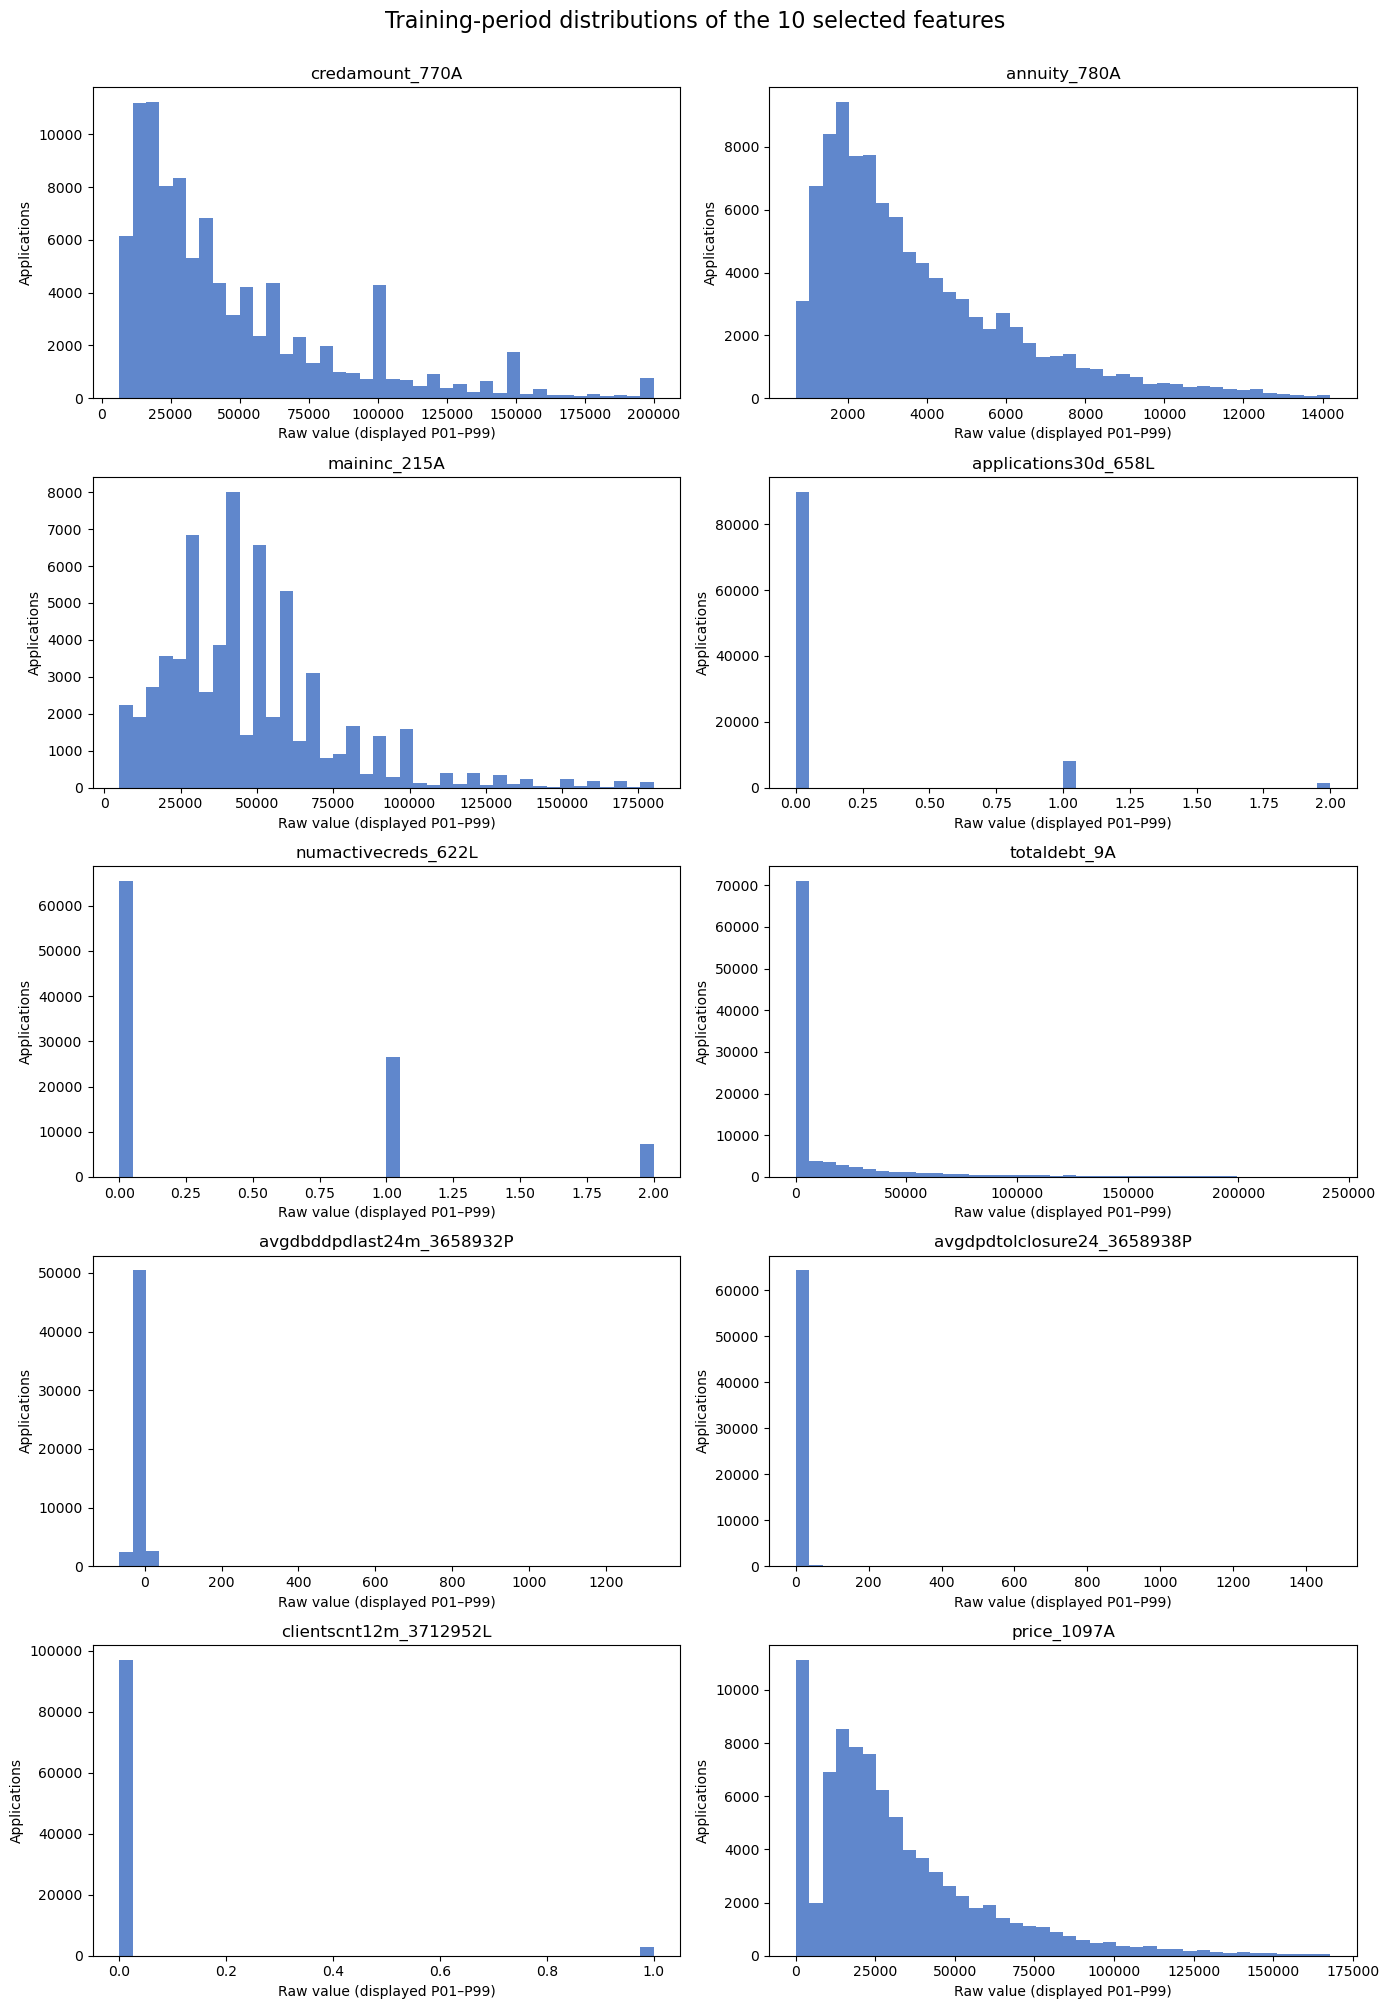

In [8]:
plot_sample = X_train.sample(n=min(100_000, len(X_train)), random_state=RANDOM_STATE)

fig, axes = plt.subplots(5, 2, figsize=(14, 20))
for feature, axis in zip(selected_features, axes.flat):
    values = plot_sample[feature].dropna()
    lower, upper = X_train[feature].quantile([0.01, 0.99])
    shown = values[(values >= lower) & (values <= upper)]
    axis.hist(shown, bins=40, color="#4472C4", alpha=0.85)
    axis.set_title(feature)
    axis.set_xlabel("Raw value (displayed P01–P99)")
    axis.set_ylabel("Applications")

fig.suptitle("Training-period distributions of the 10 selected features", fontsize=16, y=1.002)
fig.tight_layout()
plt.show()

## Build and fit the preprocessing pipeline

The order matters:

1. The imputer learns one median per source feature from training rows.
2. It appends missing indicators for source features that are missing in training.
3. The scaler learns means and standard deviations from the imputed training output.

`fit_transform` is used only for training. Validation receives `transform`, so it cannot influence the learned values.

In [9]:
preprocessor = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="median",
            add_indicator=True,
            keep_empty_features=True,
        ),
    ),
    ("scaler", StandardScaler()),
])
preprocessor.set_output(transform="pandas")

raw_training_sample = X_train.head(1_000).copy(deep=True)

X_train_prepared = preprocessor.fit_transform(X_train).astype("float32")
X_valid_prepared = preprocessor.transform(X_valid).astype("float32")

print("Raw training shape:     ", X_train.shape)
print("Prepared training shape:", X_train_prepared.shape)
print("Raw validation shape:   ", X_valid.shape)
print("Prepared validation shape:", X_valid_prepared.shape)

Raw training shape:      (1065921, 10)
Prepared training shape: (1065921, 15)
Raw validation shape:    (248535, 10)
Prepared validation shape: (248535, 15)


## Examine what the pipeline learned

These values must come only from weeks 0–51. The output below shows exactly which source features have missing training values and therefore receive an additional missing-indicator column.

In [10]:
imputer = preprocessor.named_steps["imputer"]
scaler = preprocessor.named_steps["scaler"]
prepared_feature_names = preprocessor.get_feature_names_out(selected_features).tolist()

source_parameters = pd.DataFrame({
    "feature": selected_features,
    "training_median_used_for_imputation": imputer.statistics_,
    "training_missing_percent": X_train.isna().mean().mul(100).reindex(selected_features).to_numpy(),
    "indicator_created": [
        index in set(imputer.indicator_.features_.tolist())
        for index in range(len(selected_features))
    ],
}).set_index("feature")

scaled_parameters = pd.DataFrame({
    "prepared_feature": prepared_feature_names,
    "mean_learned_before_scaling": scaler.mean_,
    "scale_learned": scaler.scale_,
}).set_index("prepared_feature")

source_parameters.to_csv(report_dir / "learned_imputation_parameters.csv")
scaled_parameters.to_csv(report_dir / "learned_scaling_parameters.csv")
pd.Series(prepared_feature_names, name="prepared_feature").to_csv(
    report_dir / "prepared_feature_names.csv", index=False
)

display(source_parameters.round(4))
print("Prepared columns:")
display(pd.DataFrame({"prepared_feature": prepared_feature_names}))

,training_median_used_for_imputation,training_missing_percent,indicator_created
feature,,,
credamount_770A,33998.0,0.0000,False
annuity_780A,3000.0,0.0000,False
maininc_215A,40000.0,33.9775,True
applications30d_658L,0.0,0.0000,False
numactivecreds_622L,0.0,0.0000,False
totaldebt_9A,0.0,0.0002,True
avgdbddpdlast24m_3658932P,-5.0,42.3792,True
avgdpdtolclosure24_3658938P,0.0,32.7221,True
clientscnt12m_3712952L,0.0,0.0000,False


Prepared columns:


,prepared_feature
0,credamount_770A
1,annuity_780A
2,maininc_215A
3,applications30d_658L
4,numactivecreds_622L
5,totaldebt_9A
6,avgdbddpdlast24m_3658932P
7,avgdpdtolclosure24_3658938P
8,clientscnt12m_3712952L
9,price_1097A


## Verify that preprocessing succeeded

The training output should be approximately centered at zero. Validation means do not need to be zero because validation represents a later population and did not fit the scaler.

In [11]:
expected_training_medians = X_train.median().reindex(selected_features).to_numpy()

assert X_train.head(1_000).equals(raw_training_sample), "The raw input sample changed unexpectedly."
assert X_train_prepared.shape[0] == X_train.shape[0]
assert X_valid_prepared.shape[0] == X_valid.shape[0]
assert X_train_prepared.shape[1] == X_valid_prepared.shape[1]
assert X_train_prepared.columns.tolist() == X_valid_prepared.columns.tolist()
assert not X_train_prepared.isna().any().any()
assert not X_valid_prepared.isna().any().any()
assert np.isfinite(X_train_prepared.to_numpy()).all()
assert np.isfinite(X_valid_prepared.to_numpy()).all()
assert np.allclose(imputer.statistics_, expected_training_medians, equal_nan=True)
assert not {"case_id", "WEEK_NUM", "target"}.intersection(X_train_prepared.columns)

verification = pd.DataFrame({
    "training_mean_after_scaling": X_train_prepared.mean(),
    "training_std_after_scaling": X_train_prepared.std(ddof=0),
    "validation_mean_after_training_scaling": X_valid_prepared.mean(),
})
display(verification.round(4))

print("All preprocessing verification checks passed.")

,training_mean_after_scaling,training_std_after_scaling,validation_mean_after_training_scaling
credamount_770A,-0.0,0.9997,0.1087
annuity_780A,0.0,0.9999,0.1195
maininc_215A,0.0,0.9997,0.0882
applications30d_658L,-0.0,0.9981,0.0715
numactivecreds_622L,-0.0,1.0037,0.1645
totaldebt_9A,0.0,0.9991,0.0999
avgdbddpdlast24m_3658932P,0.0,0.9984,0.0106
avgdpdtolclosure24_3658938P,0.0,0.9975,0.0156
clientscnt12m_3712952L,0.0,0.9958,0.0215
price_1097A,-0.0,0.9996,0.0456


All preprocessing verification checks passed.


## Inspect a few raw and prepared rows

The prepared numbers are standardized values, not currency amounts or counts. Missing source values have been replaced and corresponding `missingindicator_...` columns identify where that happened.

In [12]:
rows_with_missing = X_train.index[X_train.isna().any(axis=1)][:5]
if len(rows_with_missing) == 0:
    rows_with_missing = X_train.index[:5]

print("Raw training examples:")
display(X_train.loc[rows_with_missing])
print("Prepared versions of the same rows:")
display(X_train_prepared.loc[rows_with_missing])

Raw training examples:


,credamount_770A,annuity_780A,maininc_215A,applications30d_658L,numactivecreds_622L,totaldebt_9A,avgdbddpdlast24m_3658932P,avgdpdtolclosure24_3658938P,clientscnt12m_3712952L,price_1097A
0,30000.0,1917.6,NaN,0.0,0.0,0.0,NaN,NaN,0.0,NaN
1,19999.8,3134.0,NaN,0.0,0.0,0.0,NaN,NaN,0.0,NaN
2,78000.0,4937.0,NaN,0.0,0.0,0.0,NaN,NaN,0.0,NaN
3,40000.0,4643.6,NaN,1.0,0.0,0.0,NaN,NaN,0.0,NaN
4,44000.0,3390.2,NaN,1.0,0.0,0.0,NaN,NaN,0.0,NaN


Prepared versions of the same rows:


,credamount_770A,annuity_780A,maininc_215A,applications30d_658L,numactivecreds_622L,totaldebt_9A,avgdbddpdlast24m_3658932P,avgdpdtolclosure24_3658938P,clientscnt12m_3712952L,price_1097A,missingindicator_maininc_215A,missingindicator_totaldebt_9A,missingindicator_avgdbddpdlast24m_3658932P,missingindicator_avgdpdtolclosure24_3658938P,missingindicator_price_1097A
0,-0.427593,-0.670788,-0.216123,-0.282731,-0.653148,-0.380292,-0.082657,-0.115425,-0.112088,-0.24806,1.393961,-0.00137,1.166039,1.433889,2.567242
1,-0.664157,-0.253192,-0.216123,-0.282731,-0.653148,-0.380292,-0.082657,-0.115425,-0.112088,-0.24806,1.393961,-0.00137,1.166039,1.433889,2.567242
2,0.707892,0.365787,-0.216123,-0.282731,-0.653148,-0.380292,-0.082657,-0.115425,-0.112088,-0.24806,1.393961,-0.00137,1.166039,1.433889,2.567242
3,-0.191034,0.265061,-0.216123,1.936562,-0.653148,-0.380292,-0.082657,-0.115425,-0.112088,-0.24806,1.393961,-0.00137,1.166039,1.433889,2.567242
4,-0.096410,-0.165237,-0.216123,1.936562,-0.653148,-0.380292,-0.082657,-0.115425,-0.112088,-0.24806,1.393961,-0.00137,1.166039,1.433889,2.567242


## Result and next step

The ten raw predictors are now represented by standardized numeric columns plus missing-value indicators. The source data was not changed, and no information from weeks 52–71 was used to learn medians or scales.

```text
fit_transform → training weeks 0–51 only
transform     → validation weeks 52–71 only
untouched     → final holdout weeks 72–91
```

The report folder contains small audit files, but the million-row transformed matrices are intentionally not written to CSV. In the modeling notebook, this exact preprocessor should be placed inside one scikit-learn `Pipeline` with logistic regression. That ensures each validation fold and future prediction uses only the preprocessing learned from its corresponding training data.